# Lab 5 - motor parameters identification

**setup** 
- robot upside down, wheels spinning freely in the air (no load). Initially I was running it on the floor, but that setup was damaging one of the sensors (after one of the wheels was swapped with bigger one)
- 2 wheels are different: wheel 2 is a bigger (red) wheel, wheel 1 is the standard one.
    - M4 gets `+pw`, M3 gets `−pw`.
- each run:
  - encoders reset, PWM step applied from rest, `(t, angle)` sampled for 2s, motors off, 1s rest.
  - power levels: +-5% ... +-100% in 5% steps; battery voltage read before every run.

| wheel | ports | wheel | in the robot log |
|---|---|---|---|
| 1 | M4 / E4 | standard | `theta_l` |
| 2 | M3 / E3 | bigger, red | `theta_r` (driven with `−pw`, so its files are labelled with the PWM it actually got) |

raw robot log: `log/motor_data_240057.txt`, split into `motor_data/wheel_<N>_v_<PWM>.txt` by `split_log.py`.

**Model** (first order, inductance neglected):

$$T_m\,\dot\omega + \omega = \frac{U}{k_e}, \qquad \dot\theta = \omega$$

For a step from rest: $\theta(t) = \omega_{ss}\,(t - T_m + T_m e^{-t/T_m})$ with $\omega_{ss} = U/k_e$ and $U = \tfrac{PWM}{100}\,U_{batt}$.

In [76]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.integrate import odeint

DATA_DIR = "motor_data"
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option("display.precision", 3)

## 0. split the robot log into one file per wheel and level

robot writes a single log, one line per sample: `pw, encoder4, encoder3, t_ms, battery_V` and
`split_log.py` turns it into `motor_data/wheel_<N>_v_<PWM>.txt` (one file per wheel and PWM level, `time_ms angle_deg`, battery voltage in the header).

In [77]:
LOG_FILE = "log/motor_data_240057.txt"

os.makedirs(DATA_DIR, exist_ok=True)
for f in glob.glob(os.path.join(DATA_DIR, "wheel_*_v_*.txt")):
    os.remove(f)
%run split_log.py $LOG_FILE $DATA_DIR

pw    0:  87 samples,   35..2015 ms, battery 11.299088478088379 V
pw    0:  87 samples,   35..2015 ms, battery 11.28612995147705 V
pw    5:  87 samples,   37..2015 ms, battery 11.28612995147705 V
pw   -5:  87 samples,   34..2004 ms, battery 11.31204605102539 V
pw   10:  89 samples,   32..2012 ms, battery 11.28612995147705 V
pw  -10:  87 samples,   32..2005 ms, battery 11.28612995147705 V
pw   15:  87 samples,   35..2009 ms, battery 11.28612995147705 V
pw  -15:  86 samples,   37..2007 ms, battery 11.273172378540039 V
pw   20:  87 samples,   32..2005 ms, battery 11.28612995147705 V
pw  -20:  87 samples,   32..2011 ms, battery 11.273172378540039 V
pw   25:  86 samples,   34..2004 ms, battery 11.28612995147705 V
pw  -25:  86 samples,   32..2016 ms, battery 11.273172378540039 V
pw   30:  87 samples,   32..2014 ms, battery 11.28612995147705 V
pw  -30:  86 samples,   35..2028 ms, battery 11.28612995147705 V
pw   35:  86 samples,   34..2003 ms, battery 11.28612995147705 V
pw  -35:  86 samples,

## 1. load the runs

every file is converted to SI `(s, rad)`. robots first sample comes around 35-50ms after the step, so the known initial state $\theta(0)=0$ is added as the first point; the raw files are not modified.

In [78]:
def load_run(path):
    header = {}
    with open(path) as f:
        for line in f:
            if line.startswith("#"):
                key, value = line[1:].split(":",1)
                header[key.strip()]=value.strip()
    t_ms, angle_deg = np.loadtxt(path,comments="#",unpack=True)
    return {
        "wheel": int(header["wheel_id"]),
        "pwm": int(header["pwm_percent"]),
        "battery": float(header["battery_voltage"]),
        "t": np.r_[0.0, t_ms/1000],
        "theta": np.r_[0.0, np.radians(angle_deg)],
    }

runs = sorted(
    (load_run(p) for p in glob.glob(os.path.join(DATA_DIR, "wheel_*_v_*.txt"))),
    key=lambda r: (r["wheel"], r["pwm"])
)
print(len(runs), "runs, wheels", sorted({r["wheel"] for r in runs}))
print("battery %.2f - %.2f V" % (min(r["battery"] for r in runs), max(r["battery"] for r in runs)))
dt = np.concatenate([np.diff(r["t"][1:]) for r in runs]) * 1000
print("sample period: median %.0fms, max %.0fms" % (np.median(dt), dt.max()))

82 runs, wheels [1, 2]
battery 11.26 - 11.31 V
sample period: median 22ms, max 46ms


## 2. fit $\omega_{ss}$ and `T_m` for every run

`curve_fit` of $\theta(t)$, started from several initial `T_m` guesses and keeping the best fit (the cost surface has local minima for the short, noisy runs).
Runs whose steady speed stays below 0.3 rad/s (approx. 17deg/s) are treated as **dead zone**: the wheel creeps or does not turn at all, and `T_m` is meaningless there.

A few runs show no acceleration phase at all: between the first two samples (35-80ms) the wheel already turns at more than 2/3 of its steady speed, faster than any neighbouring level allows. Their $\omega_{ss}$ is fine, but `T_m` cannot be identified from them, so they are flagged `no_rise` and left out of the `T_m` estimate.

In [79]:
def theta_model(t, w_ss, T_m):
    return w_ss * (t-T_m + T_m*np.exp(-t/T_m))

DEAD_SPEED = 0.3 # rad/s; given that there are no values between 0 and 5PWM (0.9rad/s) i picked rand value that would fit

def fit_run(r):
    t, th = r["t"], r["theta"]
    w0 = (th[-1] - th[len(th)//2]) / (t[-1] - t[len(t) // 2]) # slope of the second half
    best = None
    for T0 in (0.02, 0.05, 0.1, 0.2, 0.4):
        try:
            p, _ = optimize.curve_fit(
                theta_model, 
                t, 
                th, 
                p0=[w0,T0], 
                bounds=([-100,1e-3], [100,2])
            )
        except RuntimeError:
            continue
        sse = np.sum((theta_model(t, *p) - th) ** 2)
        if best is None or sse<best[0]:
            best = (sse,p)
    sse, (w_ss, T_m) = best
    dead = abs(w0) < DEAD_SPEED
    v_start = (th[3]-th[1]) / (t[3]-t[1])
    no_rise = (not dead) and v_start/w0 > 2/3
    return {
        "wheel": r["wheel"], 
        "pwm": r["pwm"], 
        "battery_V": r["battery"],
        "U_V": r["pwm"]/100 * r["battery"],
        "w_ss_rad_s": 0.0 if dead else w_ss,
        "T_m_s": np.nan if dead else T_m,
        "rmse_deg": np.degrees(np.sqrt(sse/len(t))),
        "dead_zone": dead,
        "no_rise": no_rise,
    }

res = pd.DataFrame([fit_run(r) for r in runs])
res[res.no_rise].style.hide(axis="index")

wheel,pwm,battery_V,U_V,w_ss_rad_s,T_m_s,rmse_deg,dead_zone,no_rise
1,-20,11.273172,-2.254634,-4.939950,0.045031,0.708885,False,True
1,-15,11.273172,-1.690976,-4.331779,0.040424,0.978362,False,True
1,-10,11.286130,-1.128613,-3.805284,0.001000,2.939086,False,True


### table: $T_m$ and $\omega_{ss}$ for every PWM level, per wheel

In [81]:
table = res.pivot(
    index="pwm", 
    columns="wheel", 
    values=["U_V","w_ss_rad_s","T_m_s"]
)
table.columns = [f"{name} (wheel {w})" for name, w in table.columns]
table = table[[f"{n} (wheel {w})" for w in (1,2) for n in ("U_V","w_ss_rad_s","T_m_s")]]
table.to_csv("motor_parameters_table.csv")
table

,U_V (wheel 1),w_ss_rad_s (wheel 1),T_m_s (wheel 1),U_V (wheel 2),w_ss_rad_s (wheel 2),T_m_s (wheel 2)
pwm,,,,,,
-100,-11.273,-14.001,0.081,-11.273,-14.640,0.067
-95,-10.710,-13.497,0.084,-10.710,-14.218,0.084
-90,-10.169,-12.725,0.110,-10.169,-13.502,0.119
-85,-9.593,-12.029,0.134,-9.593,-12.870,0.151
-80,-9.029,-11.628,0.115,-9.029,-12.575,0.166
-75,-8.465,-11.205,0.155,-8.465,-12.186,0.188
-70,-7.900,-10.384,0.163,-7.900,-11.491,0.212
-65,-7.336,-9.693,0.193,-7.328,-10.580,0.170
-60,-6.772,-9.493,0.213,-6.772,-10.510,0.268


## 3. $\omega_{ss}$ against the actual voltage $U$, fitted $k_e$, dead zone

from the model, in steady state $\omega_{ss} = U / k_e$, so $\omega_{ss}(U)$ should be a straight line with slope $1/k_e$.

for each wheel we fit one straight line (`np.polyfit`) through all levels where the wheel actually turned, and take $k_e = 1/\text{slope}$.

levels where the wheel did not turn are left out of the fit. the shaded dead zone ends at the smallest level that did turn; with 5% steps its exact edge is somewhere below that.

In [82]:
moving = res[~res.dead_zone]
k_e = {}
lines = {}
for w in (1, 2):
    d = moving[moving.wheel == w]
    slope, intercept = np.polyfit(d.U_V, d.w_ss_rad_s, 1)
    k_e[w] = 1 / slope
    lines[w] = (slope, intercept)
    print(f"wheel {w}: slope = {slope:.3f} rad/s per V -> k_e = {k_e[w]:.3f} V*s/rad (intercept {intercept:.2f} rad/s)")

dead_U = moving.U_V.abs().min() # smallest abs(U) at which the wheels turned
print(f"wheels turn from |U| = {dead_U:.2f} V (|PWM| = {moving.pwm.abs().min()}%); the dead zone lies below that")

wheel 1: slope = 1.415 rad/s per V -> k_e = 0.707 V*s/rad (intercept 0.42 rad/s)
wheel 2: slope = 1.482 rad/s per V -> k_e = 0.675 V*s/rad (intercept 0.09 rad/s)
wheels turn from |U| = 0.56 V (|PWM| = 5%); the dead zone lies below that


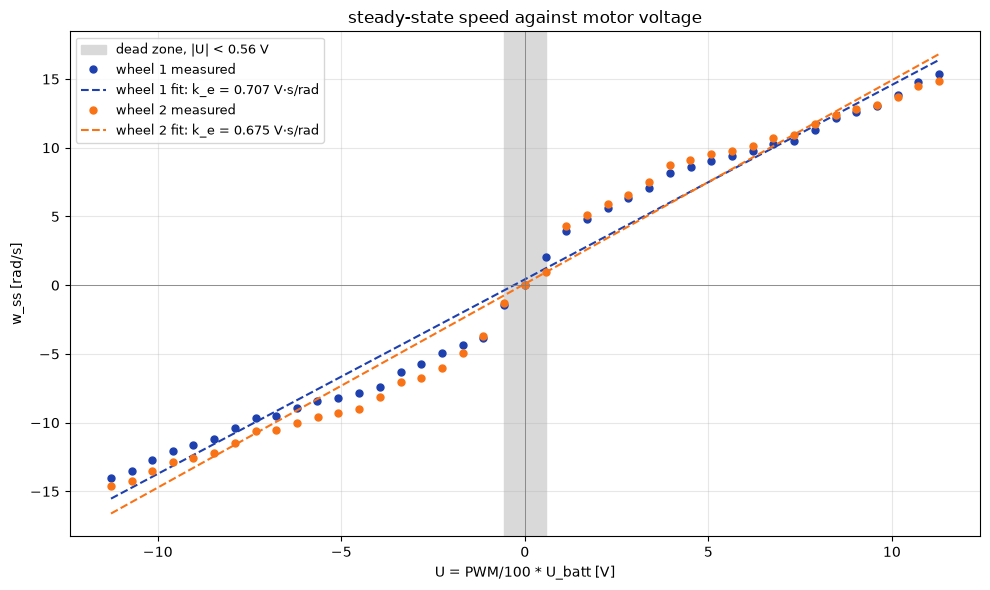

In [83]:
colors = {1: "#1E40AF", 2: "#F97316"}
fig, ax = plt.subplots(figsize=(10,6))
ax.axvspan(-dead_U, dead_U, color="0.85", label=f"dead zone, |U| < {dead_U:.2f} V")
U_line = np.linspace(res.U_V.min(), res.U_V.max(), 100)
for w in (1, 2):
    d = res[res.wheel == w]
    slope, intercept = lines[w]
    ax.plot(
        d.U_V,
        d.w_ss_rad_s,
        "o", 
        ms=5, 
        color=colors[w], 
        label=f"wheel {w} measured"
    )
    ax.plot(
        U_line, 
        slope*U_line + intercept, 
        "--", 
        lw=1.5, 
        color=colors[w],
        label=f"wheel {w} fit: k_e = {k_e[w]:.3f} V·s/rad"
    )
ax.axhline(0, color="0.5", lw=0.6); ax.axvline(0, color="0.5", lw=0.6)
ax.set_xlabel("U = PWM/100 * U_batt [V]"); ax.set_ylabel("w_ss [rad/s]")
ax.set_title("steady-state speed against motor voltage")
ax.grid(alpha=0.3); ax.legend(fontsize=9, loc="upper left")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/omega_vs_U.png", dpi=150)
plt.show()

### $U/\omega_{ss}$ for every level

if the model was exact, $U/\omega_{ss} = k_e$ would be the same number at every level. Plotting it per level shows where it is not (dead-zone levels have $\omega_{ss}=0$ and are skipped).

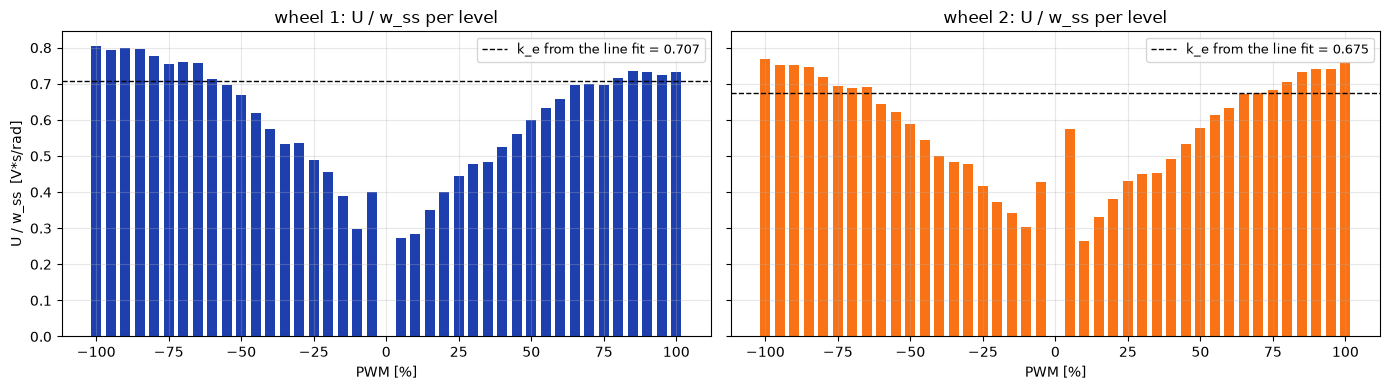

In [84]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, w in zip(axs, (1, 2)):
    d = moving[moving.wheel == w]
    ax.bar(
        d.pwm, 
        d.U_V/d.w_ss_rad_s, 
        width=3.5, 
        color=colors[w]
    )
    ax.axhline(
        k_e[w], 
        color="k", 
        ls="--", 
        lw=1, 
        label=f"k_e from the line fit = {k_e[w]:.3f}"
    )
    ax.set_title(f"wheel {w}: U / w_ss per level"); ax.set_xlabel("PWM [%]")
    ax.grid(alpha=0.3); ax.legend(fontsize=9)
axs[0].set_ylabel("U / w_ss  [V*s/rad]")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/U_over_omega.png", dpi=150)
plt.show()

### `T_m` against PWM

model also assumes one constant `T_m`. we take the **median** over the levels where the wheel turned. 3 `no_rise` runs (hollow markers) had no visible speed-up in the data, so their `T_m` is not used.

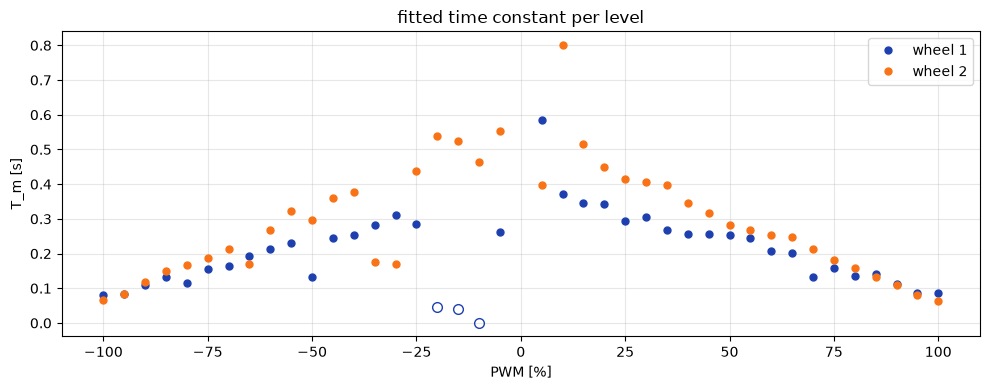

In [85]:
fig, ax = plt.subplots(figsize=(10, 4))
for w in (1, 2):
    d = moving[moving.wheel == w]
    ok = d[~d.no_rise]
    ax.plot(
        ok.pwm, 
        ok.T_m_s, 
        "o", 
        ms=5, 
        color=colors[w], 
        label=f"wheel {w}"
    )
    ax.plot(
        d[d.no_rise].pwm, 
        d[d.no_rise].T_m_s, 
        "o", 
        ms=7, 
        mfc="none", 
        color=colors[w]
    )
ax.set_xlabel("PWM [%]"); ax.set_ylabel("T_m [s]"); ax.set_title("fitted time constant per level")
ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/Tm_vs_pwm.png", dpi=150)
plt.show()

## 4. identified parameters

In [86]:
T_m = {w: moving[(moving.wheel == w) & ~moving.no_rise].T_m_s.median() for w in (1, 2)}
summary = pd.DataFrame({
    w: {
        "k_e [V*s/rad]": k_e[w],
        "T_m (median) [s]": T_m[w],
        "dead zone [V]": f"|U| < {dead_U:.2f}",
        "omega_ss at +100% [rad/s]": res[(res.wheel==w) & (res.pwm==100)].w_ss_rad_s.item(),
        "omega_ss at -100% [rad/s]": res[(res.wheel==w) & (res.pwm==-100)].w_ss_rad_s.item(),
    } for w in (1, 2)
})
summary.columns = ["wheel 1", "wheel 2"]
summary.to_csv("motor_parameters_summary.csv")
summary

,wheel 1,wheel 2
k_e [V*s/rad],0.707,0.675
T_m (median) [s],0.213,0.269
dead zone [V],|U| < 0.56,|U| < 0.56
omega_ss at +100% [rad/s],15.375,14.844
omega_ss at -100% [rad/s],-14.001,-14.64


## 5. step response: measurement vs. simulated model

wheel 1 at `+50%` and `+75%`. Each plot shows the same run three ways:
* **measured** $\theta(t)$ - the encoder readings from the robot;
* **per-run fit** - $\omega_{ss}$ and `T_m` fitted to this run only (checks that the model's *shape* can describe a real run);
* **identified model** - motor ODE simulated with `odeint` using the wheel's final $k_e$ and `T_m` from the table above and this run's voltage $U$ (checks whether our *one set of parameters* predicts the run).

The two levels show the two different ways one set of parameters fails:
* `50%`: the real $U/\omega_{ss}$ (0.60) is far from the fitted $k_e$ (0.707), so the model's final speed is 18% too low and the gap **keeps growing** (~120deg after 2s).
* `75%`: the final speed is right (within ~1%), but the real wheel spins up faster than the median `T_m` (0.16s vs 0.21s), so the gap opens in the first ~0.5s and then **stays constant** (~55deg).

PWM 50%: model omega_ss = 7.98 rad/s, measured 9.40 rad/s; model vs measurement after 2.0s: -123deg
PWM 75%: model omega_ss = 11.98 rad/s, measured 12.15 rad/s; model vs measurement after 2.0s: -56deg


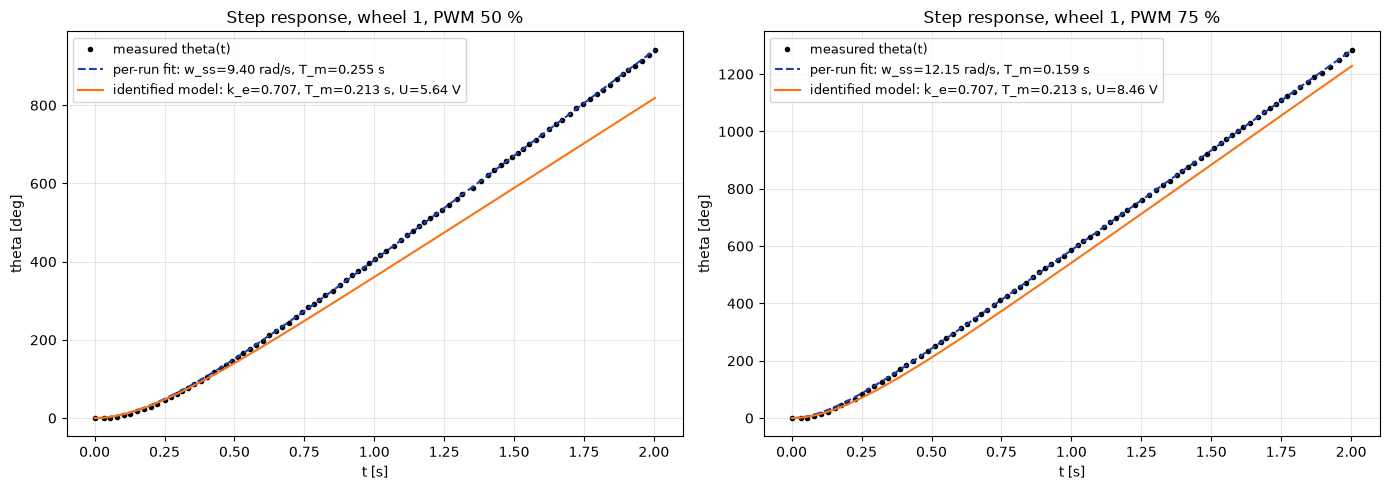

In [87]:
WHEEL, PWMS = 1, (50,75)

def motor(state, t, U, T_m, k_e):
    w, theta = state
    return [(-w + U/k_e) / T_m, w] # T_m * dw/dt + w = U/k_e,  dtheta/dt = w

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax, PWM in zip(axs, PWMS):
    r = next(r for r in runs if r["wheel"] == WHEEL and r["pwm"] == PWM)
    row = res[(res.wheel == WHEEL) & (res.pwm == PWM)].iloc[0]
    U = row.U_V
    t_sim = np.linspace(0, r["t"][-1], 500)
    sim = odeint(motor, [0.0, 0.0], t_sim, args=(U, T_m[WHEEL], k_e[WHEEL]))

    ax.plot(r["t"], np.degrees(r["theta"]), "o", ms=3, color="k", label="measured theta(t)")
    ax.plot(
        t_sim,
        np.degrees(theta_model(t_sim, row.w_ss_rad_s, row.T_m_s)),
        "--",
        color=colors[1],
        label=f"per-run fit: w_ss={row.w_ss_rad_s:.2f} rad/s, T_m={row.T_m_s:.3f} s"
    )
    ax.plot(
        t_sim,
        np.degrees(sim[:, 1]),
        "-",
        color=colors[2],
        label=f"identified model: k_e={k_e[WHEEL]:.3f}, T_m={T_m[WHEEL]:.3f} s, U={U:.2f} V"
    )
    ax.set_xlabel("t [s]"); ax.set_ylabel("theta [deg]")
    ax.set_title(f"Step response, wheel {WHEEL}, PWM {PWM} %")
    ax.grid(alpha=0.3); ax.legend(fontsize=9)

    err = np.degrees(np.interp(r["t"], t_sim, sim[:, 1]) - r["theta"])
    print("PWM %d%%: model omega_ss = %.2f rad/s, measured %.2f rad/s; model vs measurement after %.1fs: %.0fdeg"
          % (PWM, U / k_e[WHEEL], row.w_ss_rad_s, r["t"][-1], err[-1]))
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/step_response_w{WHEEL}.png", dpi=150)
plt.show()

### where the formulas come from (sympy)

solving the motor equation $T_m\,\dot\omega + \omega = U/k_e$ symbolically with $\omega(0)=0$ gives the speed curve; integrating it once more gives the angle $\theta(t)$ that we fitted with `curve_fit`.

In [89]:
import sympy as sp
from IPython.display import display

t_, tau = sp.symbols("t tau", nonnegative=True)
T_m_, k_e_, U_ = sp.symbols("T_m k_e U", positive=True)
omega = sp.Function("omega")

ode = sp.Eq(T_m_ * omega(t_).diff(t_) + omega(t_), U_ / k_e_)
omega_sol = sp.dsolve(ode, omega(t_), ics={omega(0): 0})
theta_sol = sp.expand(sp.integrate(omega_sol.rhs.subs(t_, tau), (tau, 0, t_)))

display(omega_sol) # omega(t) = U/k_e * (1-exp(-t/T_m))
display(sp.Eq(sp.Symbol("theta(t)"), theta_sol))

U_50 = res[(res.wheel == 1) & (res.pwm == 50)].U_V.item()
w_ss_50 = round(U_50 / k_e[1], 2)
display(sp.Eq(omega(t_), w_ss_50 - w_ss_50 * sp.exp(-round(1/T_m[1], 2) * t_)))

Eq(omega(t), U/k_e - U*exp(-t/T_m)/k_e)

Eq(theta(t), -T_m*U/k_e + T_m*U*exp(-t/T_m)/k_e + U*t/k_e)

Eq(omega(t), 7.98 - 7.98*exp(-4.7*t))

### speed curve $\omega(t)$

the same simulation as the step response, but plotting the speed (`sim[:, 0]`) instead of the angle: wheel 1 at `+50%` and `+75%`. Measured speed is the change in angle between neighbouring samples (noisy, because the encoder counts whole degrees).
The dotted line marks $t = T_m$: by then the model reaches 63% of its final speed.

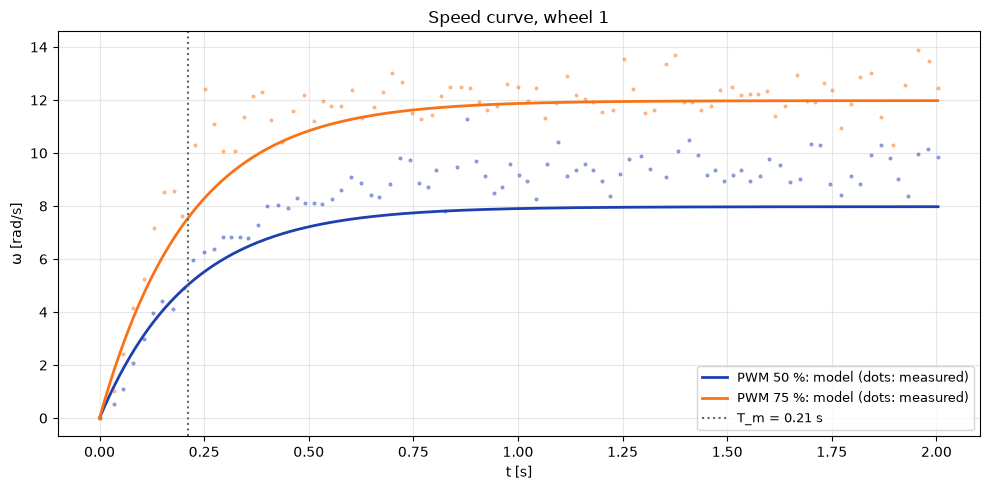

In [90]:
pwm_colors = {50:colors[1], 75:colors[2]}
fig, ax = plt.subplots(figsize=(10,5))
for PWM in PWMS:
    r = next(r for r in runs if r["wheel"] == WHEEL and r["pwm"] == PWM)
    U = res[(res.wheel == WHEEL) & (res.pwm == PWM)].U_V.item()
    t_sim = np.linspace(0, r["t"][-1], 500)
    sim = odeint(motor, [0.0, 0.0], t_sim, args=(U, T_m[WHEEL], k_e[WHEEL]))
    ax.plot(
        r["t"], 
        np.gradient(r["theta"],r["t"]), 
        ".", 
        ms=4, 
        alpha=0.4, 
        color=pwm_colors[PWM]
    )
    ax.plot(
        t_sim, 
        sim[:,0], 
        "-", 
        lw=2, 
        color=pwm_colors[PWM],
        label=f"PWM {PWM} %: model (dots: measured)"
    )
ax.axvline(T_m[WHEEL], ls=":", color="0.4", label=f"T_m = {T_m[WHEEL]:.2f} s")
ax.set_xlabel("t [s]"); ax.set_ylabel("ω [rad/s]")
ax.set_title(f"Speed curve, wheel {WHEEL}")
ax.grid(alpha=0.3); ax.legend(fontsize=9)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/speed_curve_w{WHEEL}.png", dpi=150)
plt.show()

## 6. conclusions

weak/failing points of linear model:
- dead zone below 5% PWM
    - $\omega_{ss}(U)\$ isn't a straight line, so one `k_e` underestimates mid-range speeds. At 50% the model is ~120deg behind after 2s.
    - `T_m` isn't constant: ~0.07s at +-100%, up to ~0.5s at low PWM.

- how much the wheels differ
    - `k_e` is close (0.707 vs 0.675, ~5%). (again worth noting that in current setup (with wheels in the air) the steady speed depends on the motor, not the wheel).
    - big red wheel has a higher `T_m` (0.27s vs 0.21s) because it's heavier, thus slower to spin up.

- what it means for odometry next week
    <!-- - the wheel radii differ, so each wheel needs its own radius in the odometry, or the heading estimate will drift. -->
    - the values were measured with no load, so the real robot on the floor will be slower and have a bigger dead zone than this model predicts. In that case the initial data collected (v1 or v2 log files) - with setup of default wheels on the ground - would be more useful for odometry.